# 04 · Three or more groups: more chances, more noise
**Two insights:** (1) testing every pair separately creates more opportunities for false alarms; (2) ANOVA compares separation between group means with variation within groups.

ANOVA tests **all population means equal** versus **at least one differs**. It does not identify which groups differ. Corrected pairwise tests answer that follow-up question. A significant ANOVA is not permission to run uncorrected follow-up tests.

**Assumptions held fixed:** independent observations and groups, normal populations, equal population variances within every scenario. Classical one-way ANOVA and pooled Student pairwise t-tests fit this design. All tests use alpha 0.05; pairwise tests are two-sided. Welch’s ANOVA for unequal variances is a later comparison. All data are simulated.

In [1]:
from pathlib import Path
from itertools import combinations
import json, platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 20261128
REPETITIONS = 20_000
N = 30
ALPHA = .05
MAX_GROUPS = 10
OUT = Path("outputs/04-anova-and-multiple-comparisons")
OUT.mkdir(parents=True, exist_ok=True)

def interval_row(rejected, **labels):
    count = int(rejected.sum())
    ci = stats.binomtest(count, len(rejected)).proportion_ci(method="wilson")
    return dict(**labels, repetitions=len(rejected), rejections=count,
                rate_pct=100*rejected.mean(), mc_low_pct=100*ci.low, mc_high_pct=100*ci.high)

def anova_from_moments(means, variances):
    k = means.shape[1]
    ss_between = N*((means-means.mean(axis=1, keepdims=True))**2).sum(axis=1)
    ss_within = (N-1)*variances.sum(axis=1)
    ms_between = ss_between/(k-1)
    ms_within = ss_within/(k*(N-1))
    f = ms_between/ms_within
    return f, stats.f.sf(f, k-1, k*(N-1)), ms_between, ms_within


## 1 · A–B, A–C, B–C: how often is at least one “significant”?
Start with **all population means equal to 60**, all SDs 5, and 30 observations per group. Repeat 20,000 times. Compare:

- **Uncorrected pairs:** flag the experiment if any pair has p < 0.05.
- **Bonferroni pairs:** flag it if any pair has p < 0.05/m, where m is the number of pairs.
- **One ANOVA:** flag it if its omnibus p < 0.05.

These are experiment-level false-alarm probabilities under the complete null. Pairwise tests sharing groups are dependent, so **1 − 0.95^m is not their exact false-alarm rate**. The independent-test formula is shown only as a labelled reference. Bonferroni controls the probability of any false rejection without requiring independence; it can be conservative.

In [2]:
rng = np.random.default_rng(SEED)
x = rng.normal(60, 5, (REPETITIONS, MAX_GROUPS, N))
means, variances = x.mean(axis=2), x.var(axis=2, ddof=1)
rows = []
null_three_trials = None
for k in range(2, MAX_GROUPS+1):
    pair_indices = list(combinations(range(k), 2))
    p_pairs = []
    for i, j in pair_indices:
        pooled_var = (variances[:, i]+variances[:, j])/2  # equal n
        t = (means[:, i]-means[:, j])/np.sqrt(pooled_var*2/N)
        p_pairs.append(2*stats.t.sf(np.abs(t), 2*N-2))
    p_pairs = np.column_stack(p_pairs)
    m = len(pair_indices)
    f, p_anova, _, _ = anova_from_moments(means[:, :k], variances[:, :k])
    flags = {"Uncorrected pairs": (p_pairs < ALPHA).any(axis=1),
             "Bonferroni pairs": (p_pairs < ALPHA/m).any(axis=1),
             "One ANOVA": p_anova < ALPHA}
    for method, rejected in flags.items():
        rows.append(interval_row(rejected, groups=k, comparisons=m, method=method))
    if k == 3:
        null_three_trials = pd.DataFrame(dict(p_ab=p_pairs[:,0], p_ac=p_pairs[:,1],
            p_bc=p_pairs[:,2], p_anova=p_anova))
        direct = stats.f_oneway(*[x[:,i,:] for i in range(3)], axis=1)
        assert np.allclose(p_anova, direct.pvalue)
        assert np.allclose(p_pairs[:,0], stats.ttest_ind(x[:,0,:], x[:,1,:], axis=1, equal_var=True).pvalue)
    assert np.all(~flags["Bonferroni pairs"] | flags["Uncorrected pairs"])
null_metrics = pd.DataFrame(rows)
null_metrics.to_csv(OUT / "null_metrics.csv", index=False)
null_three_trials.to_csv(OUT / "three_group_null_trials.csv", index=False)
display(null_metrics[null_metrics.groups == 3].round(3))

,groups,comparisons,method,repetitions,rejections,rate_pct,mc_low_pct,mc_high_pct
3,3,3,Uncorrected pairs,20000,2395,11.975,11.532,12.432
4,3,3,Bonferroni pairs,20000,856,4.280,4.008,4.569
5,3,3,One ANOVA,20000,970,4.850,4.561,5.156


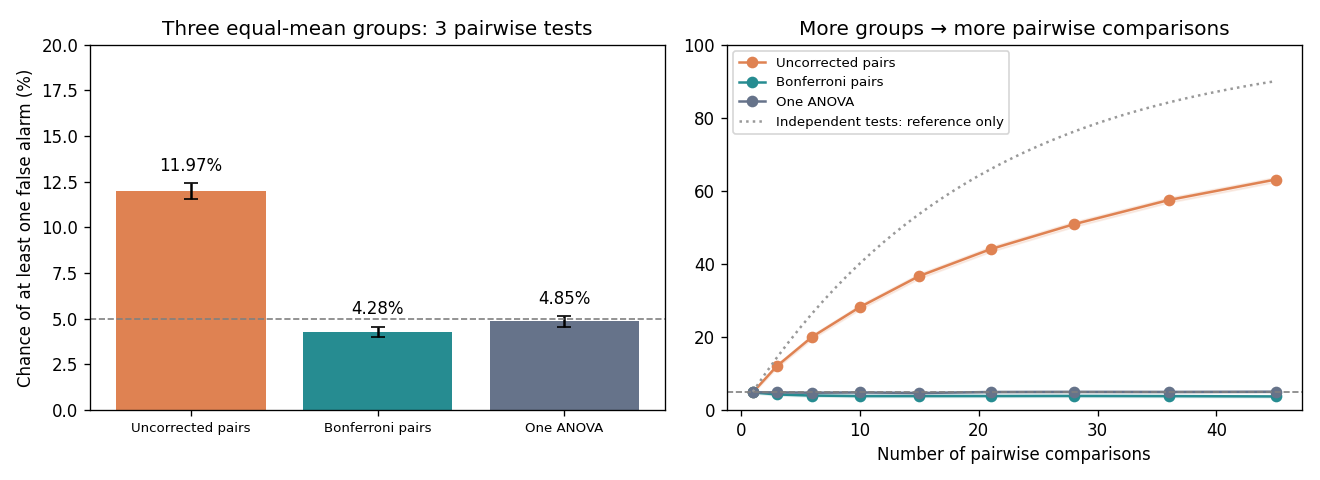

In [3]:
colors = {"Uncorrected pairs":"#df8252", "Bonferroni pairs":"#268c91", "One ANOVA":"#66738a"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
three = null_metrics[null_metrics.groups == 3]
y = three.rate_pct.to_numpy()
err = np.maximum(0, np.vstack([y-three.mc_low_pct.to_numpy(), three.mc_high_pct.to_numpy()-y]))
bars = axes[0].bar(three.method, y, color=[colors[m] for m in three.method], yerr=err, capsize=4)
axes[0].bar_label(bars, labels=[f"{v:.2f}%" for v in y], padding=5)
axes[0].set(title="Three equal-mean groups: 3 pairwise tests", ylabel="Chance of at least one false alarm (%)", ylim=(0, 20))
axes[0].tick_params(axis="x", labelsize=8)
for method, color in colors.items():
    sub = null_metrics[null_metrics.method == method]
    axes[1].plot(sub.comparisons, sub.rate_pct, marker="o", color=color, label=method)
    axes[1].fill_between(sub.comparisons, sub.mc_low_pct, sub.mc_high_pct, color=color, alpha=.12)
m_values = np.arange(1, 46)
axes[1].plot(m_values, 100*(1-(1-ALPHA)**m_values), linestyle=":", color="#999999", label="Independent tests: reference only")
axes[1].set(title="More groups → more pairwise comparisons", xlabel="Number of pairwise comparisons", ylim=(0, 100))
for ax in axes: ax.axhline(5, color="gray", linestyle="--", linewidth=1)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "false_alarm_growth.png", dpi=180)
plt.show()
# Website-ready slider data: discrete all-pairs settings and separate independent-test reference.
null_metrics.to_json(OUT / "slider_all_pairs.json", orient="records", indent=2)
independent = pd.DataFrame({"comparisons":np.arange(1, 101)})
independent["false_alarm_pct"] = 100*(1-(1-ALPHA)**independent.comparisons)
independent.to_json(OUT / "slider_independent_reference.json", orient="records", indent=2)

## 2 · Same mean separation, different within-group noise
Now population means are **60, 60, 63**. Keep 30 observations per group and compare common SD **3 versus 10**. Within each scenario all three variances remain equal. Only within-group noise changes.

ANOVA’s F = **between-group mean square / within-group mean square**. Mean squares account for degrees of freedom; F is not simply the raw spread of the means divided by raw observation spread. Even when population means are equal, sample means differ by chance. The F reference distribution accounts for that.

The example plot uses the same residual pattern scaled to each SD and centred within each group to isolate the visual comparison. Its sample means are exactly 60, 60, 63 **by construction**. Only this illustration is centred; the repeated simulations below use ordinary uncentred random samples.

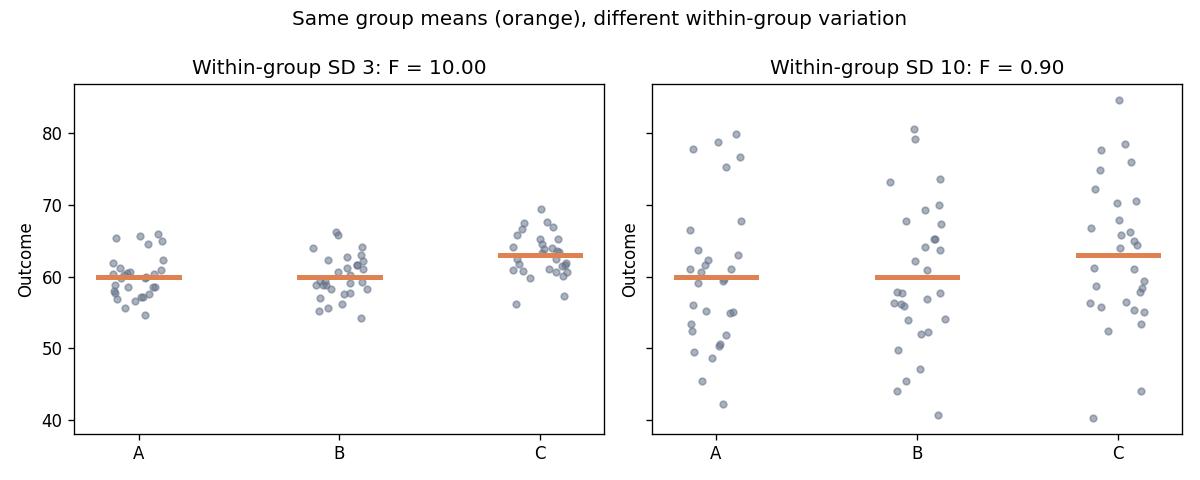

In [4]:
example_rng = np.random.default_rng(SEED+1)
residual = example_rng.normal(size=(3, N))
residual = (residual-residual.mean(axis=1, keepdims=True))/residual.std(axis=1, ddof=1, keepdims=True)
mu = np.array([60, 60, 63])
jitter = example_rng.uniform(-.14, .14, (3, N))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, sd in zip(axes, [3, 10]):
    values = mu[:,None]+sd*residual
    for g in range(3):
        ax.scatter(g+jitter[g], values[g], alpha=.55, s=16, color="#66738a")
        ax.plot([g-.2, g+.2], [mu[g],mu[g]], color="#df8252", linewidth=3)
    f, pv, _, _ = anova_from_moments(values.mean(axis=1)[None,:], values.var(axis=1,ddof=1)[None,:])
    ax.set(xticks=[0,1,2], xticklabels=["A", "B", "C"], ylabel="Outcome", title=f"Within-group SD {sd}: F = {f[0]:.2f}")
fig.suptitle("Same group means (orange), different within-group variation")
fig.tight_layout()
fig.savefig(OUT / "within_vs_between.png", dpi=180)
plt.show()

Uncorrected pairs: 11.97% false alarms with three groups.
Bonferroni pairs: 4.28% false alarms with three groups.
One ANOVA: 4.85% false alarms with three groups.
Within-group SD 3: 98.11% power.
Within-group SD 10: 20.38% power.


,within_group_sd,method,repetitions,rejections,rate_pct,mc_low_pct,mc_high_pct,mean_f,average_between_ms,average_within_ms
0,3,One ANOVA,20000,19622,98.110,97.912,98.290,11.280,99.109,8.996
1,10,One ANOVA,20000,4075,20.375,19.822,20.939,1.951,190.494,99.951


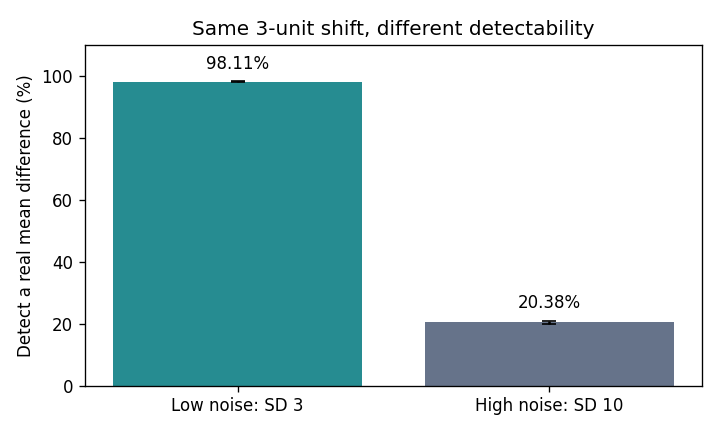

In [5]:
rng_power = np.random.default_rng(SEED+2)
z = rng_power.normal(size=(REPETITIONS, 3, N))
power_rows, power_trials = [], []
for sd in [3, 10]:
    values = mu[None,:,None]+sd*z
    f, p, msb, msw = anova_from_moments(values.mean(axis=2), values.var(axis=2, ddof=1))
    row = interval_row(p < ALPHA, within_group_sd=sd, method="One ANOVA")
    row.update(mean_f=f.mean(), average_between_ms=msb.mean(), average_within_ms=msw.mean())
    power_rows.append(row)
    power_trials.append(pd.DataFrame(dict(within_group_sd=sd, repetition=np.arange(REPETITIONS), f=f, p_value=p)))
power = pd.DataFrame(power_rows)
power.to_csv(OUT / "power_metrics.csv", index=False)
pd.concat(power_trials, ignore_index=True).to_csv(OUT / "power_trials.csv", index=False)
display(power.round(3))
fig, ax = plt.subplots(figsize=(6, 3.6))
y = power.rate_pct.to_numpy()
err = np.maximum(0, np.vstack([y-power.mc_low_pct.to_numpy(), power.mc_high_pct.to_numpy()-y]))
bars = ax.bar(["Low noise: SD 3", "High noise: SD 10"], y, color=["#268c91", "#66738a"], yerr=err, capsize=4)
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in y], padding=5)
ax.set(ylabel="Detect a real mean difference (%)", ylim=(0, 110), title="Same 3-unit shift, different detectability")
ax.set_yticks([0, 20, 40, 60, 80, 100])
fig.tight_layout()
fig.savefig(OUT / "anova_power.png", dpi=180)
plt.show()
settings = dict(seed=SEED, illustration_seed=SEED+1, power_seed=SEED+2,
    repetitions=REPETITIONS, n_per_group=N, alpha=ALPHA, group_counts=list(range(2,11)),
    null_mean=60, null_sd=5, alternative_means=mu.tolist(), alternative_sds=[3,10],
    shared_draws_across_settings=True, python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__)
(OUT / "settings.json").write_text(json.dumps(settings, indent=2))
assert np.isfinite(power.select_dtypes("number")).all().all()
for _, r in three.iterrows():
    print(f'{r["method"]}: {r.rate_pct:.2f}% false alarms with three groups.')
for _, r in power.iterrows():
    print(f'Within-group SD {r.within_group_sd}: {r.rate_pct:.2f}% power.')

## Takeaways
**More chances:** three individually 5% tests do not make one collectively 5% investigation. ANOVA handles the overall equal-means question; corrected pairwise comparisons handle which pairs differ. Their rejection rates need not match because they use different decision rules.

**Signal relative to noise:** the same population mean separation is easier to detect when observations cluster tightly within each group. “Within versus between” explains ANOVA’s statistic; its hypothesis is about population means, not a test for equal variances.

All false-alarm results here concern the complete null, with every group mean equal. No claim is made that an omnibus gate alone controls false pairwise findings when some means differ. Bonferroni controls family-wise errors, including under partial nulls. Power is shown only for the selected ANOVA alternative. Monte Carlo intervals quantify simulation uncertainty, not model validity. No repeated measurements, unequal variances or causal attribution are addressed here.

**Review prompt:** Why can three pairwise tests each be valid at 5%, while their combined chance of a false alarm exceeds 5%?

## Website presentation brief · including comparison slider
**Story 1:** “Every extra comparison is another chance for a false alarm.” Start with A–B, A–C, B–C highlighted one by one, then reveal the simulated experiment-level false-alarm rate versus the 5% target. Compare uncorrected pairs, Bonferroni pairs and one omnibus ANOVA.

**Requested slider (planned, not implemented in this notebook):** use `slider_all_pairs.json` to move through **2–10 groups**, explicitly displaying **m = k(k−1)/2 comparisons**: 1, 3, 6, 10, 15, 21, 28, 36, 45. Label it “Number of groups” and prominently update “Number of pairwise comparisons.” These are discrete all-pairs settings; do not suggest that any arbitrary integer comparison count is an all-pairs design. Show observed rates, Monte Carlo intervals, 30 observations per group, and “All true means are equal.” More groups also means more total observations; group size stays fixed.

An optional separate mode may offer a **1–100 comparisons slider for independent tests**, using `slider_independent_reference.json` and the exact formula 1−0.95^m. Clearly label the independence assumption. Do not use that formula as the exact risk for A–B, A–C, B–C because they share groups. Do not interpolate uncomputed all-pairs results as simulation evidence.

**Story 2:** “Same separation, different noise.” Show the fixed-mean dot plots with matched axes and a low/high within-group-noise toggle. Explain their centred illustration construction; use the uncentred repeated simulations for the power percentages. Put the F ratio and degrees of freedom in optional detail.

Keep the two stories distinct: family-wise false alarms versus sensitivity to a real difference. No website is changed here; saved metrics, curves and presentation directions are ready for later use.
